In [2]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import random

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

random.seed(0)

#### Coding the tricks

- Simple trick
- Absolute trick
- Square trick

##### Simple trick

In [3]:
def simple_trick(base_price, price_per_room, num_rooms, price):
    small_random_1 = random.random() * 0.1
    small_random_2 = random.random() * 0.1

    predicted_price = base_price + price_per_room * num_rooms
    if (price > predicted_price) and (num_rooms > 0):
        price_per_room += small_random_1    # add η1 to slope
        base_price += small_random_2    # add η2 to y-intercept
    if price > predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    if price < predicted_price and num_rooms > 0:
        price_per_room -= small_random_1
        base_price -= small_random_2
    if price < predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    return price_per_room, base_price

##### Square trick

In [4]:
def square_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    # Calculates the prediction
    predicted_price = (price_per_room * num_rooms) + base_price 
    base_price += learning_rate * (price - predicted_price) # Translates the line
    price_per_room += learning_rate * num_rooms * (price - predicted_price) #  Rotates the line
    # predicted_price = (price_per_room * num_rooms) + base_price

    return price_per_room, base_price

##### Absolute trick

In [5]:
def absolute_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    predicted_price = base_price + (price_per_room * num_rooms)
    if (price > predicted_price):
        price_per_room += learning_rate * num_rooms
        base_price += learning_rate
    else:
        price_per_room -= learning_rate * num_rooms
        base_price -= learning_rate
        
    return price_per_room, base_price

___
#### Defining the dataset

In [6]:
features = np.array([1, 2, 3, 5, 6, 7])
labels = np.array([155, 197, 244, 356, 407, 448])

print(features)
print(labels)

[1 2 3 5 6 7]
[155 197 244 356 407 448]


#### Plotting the dataset

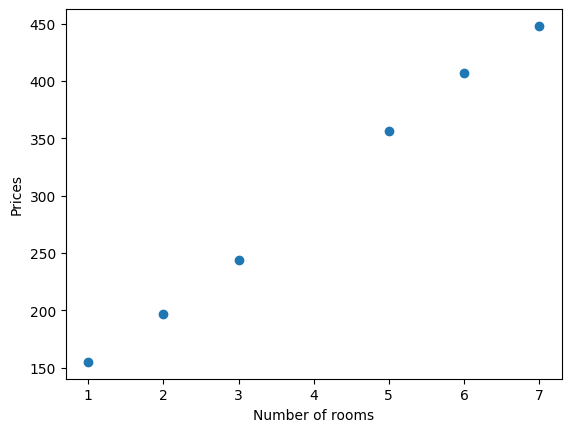

In [7]:
def draw_line(slope, y_intercept, color="grey", linewidth=0.7, starting=0, ending=8):
    x = np.linspace(starting, ending, 1000)
    plt.plot(x, (slope * x) + y_intercept, linestyle="-", color=color, linewidth=linewidth)

def plot_points(features, labels):
    X = features
    y = labels
    plt.scatter(X, y)
    plt.xlabel("Number of rooms")
    plt.ylabel("Prices")

plot_points(features, labels)

____
### Running the linear regression algorithm

The linear regression algorithm consists of:
- Starting with random weights
- Iterating the square (or simple, or absolute) trick many times.

Note that we have used the Python random package to generate random numbers for our initial values (slope and y-intercept) and for selecting our points inside the loop:

Each iteration of the loop is called an epoch, and we set this number at the beginning of
our algorithm. 
The next step is to run this algorithm to build a model that fits our dataset.

Price per room:  51.05347808556453
Base price:  99.0970202799414


(np.float64(51.05347808556453), np.float64(99.0970202799414))

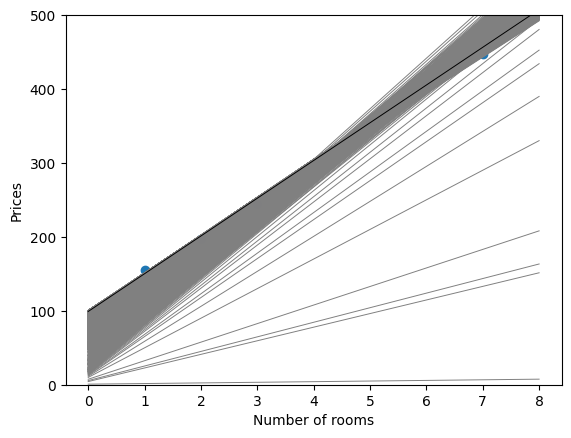

In [8]:
def linear_regression(features, labels, learning_rate=0.01, epochs=10000):
    # Generates (pseudo) rdm values for the slope and the y-intercept
    price_per_room = random.random()    
    base_price = random.random()
    # Repeats the update step many times
    for epoch in range(epochs):
        # Uncomment any of the following lines to plot different epochs
        #if epoch == 1:
        #if epoch <= 10:
        #if epoch <= 50:
        #if epoch > 50:
        if True:
            draw_line(price_per_room, base_price, starting=0, ending=8)
        i = random.randint(0, len(features)-1) # Picks a random point on our dataset
        num_rooms = features[i]
        price = labels[i]

        # Applies the square trick to move the line closer to our point
        price_per_room, base_price = square_trick(base_price, 
                                                  price_per_room, 
                                                  num_rooms, 
                                                  price, 
                                                  learning_rate=learning_rate)

    draw_line(price_per_room, base_price, "black", starting=0, ending=8)
    plot_points(features, labels)
    print("Price per room: ", price_per_room)
    print("Base price: ", base_price)

    return price_per_room, base_price

# This line is for the x-axis to appear in the figure
plt.ylim(0, 500)

linear_regression(features, labels, learning_rate=0.01, epochs=10000)  

#### Root Mean Square Error (RMSE) function

RMSE measures the average magnitude of prediction errors.

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

- $n$: number of data points
- $y_i$: actual value
- $\hat{y}_i$: predicted value

**Interpretation:** Subtract predictions from actual values, square the errors, calculate their mean, and take the square root.

In NumPy, `np.dot(differences, differences)` calculates the sum of squared errors.

In [39]:
# The root mean square error function
def rmse(labels, predictions):
    n = len(labels)
    differences = np.subtract(labels, predictions)
    
    return np.sqrt(1.0/n * (np.dot(differences, differences)))

Taking the Root Mean Square Errors of the predictions:

Price per room:  50.47172224993165
Base price:  99.39997930257694


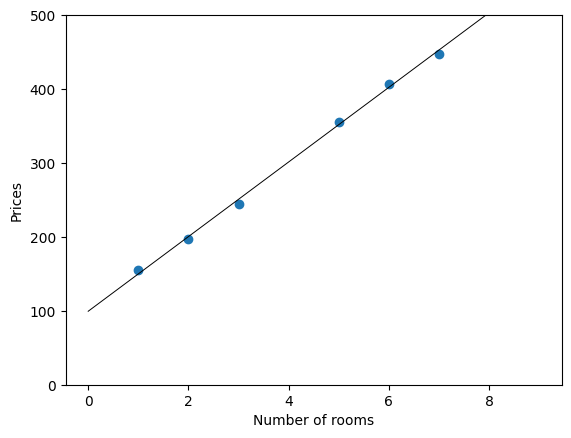

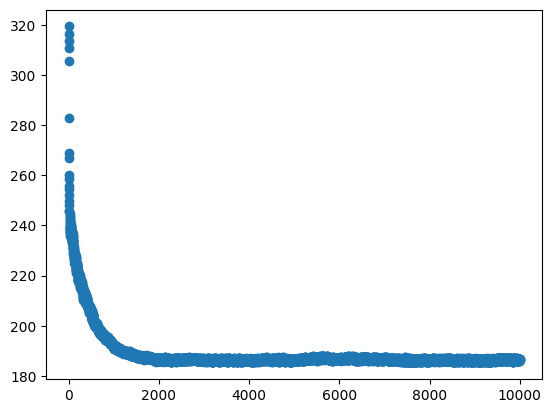

(np.float64(50.47172224993165), np.float64(99.39997930257694))

In [40]:
def linear_regression(features, labels, learning_rate=0.01, epochs=10000):
    # Generates (pseudo) rdm values for the slope and the y-intercept
    price_per_room = random.random()    
    base_price = random.random()
    errors = []

    # Repeats the update step many times
    for epoch in range(epochs):
        predictions = (price_per_room * features[0]) + base_price
        errors.append(rmse(labels, predictions))

        i = random.randint(0, len(features)-1) # Picks a random point on our dataset
        num_rooms = features[i]
        price = labels[i]

        # Applies the square trick to move the line closer to our point
        price_per_room, base_price = square_trick(base_price, 
                                                  price_per_room, 
                                                  num_rooms, 
                                                  price, 
                                                  learning_rate=learning_rate)

    draw_line(price_per_room, base_price, "black", starting=0, ending=9)
    plot_points(features, labels)
    print("Price per room: ", price_per_room)
    print("Base price: ", base_price)
    plt.show()

    plt.scatter(range(len(errors)), errors)
    plt.show()

    return price_per_room, base_price

# This line is for the x-axis to appear in the figure
plt.ylim(0, 500)

linear_regression(features, labels, learning_rate=0.01, epochs=10000) 

_____
#### Real-life application: Using scikit-learn to predict housing prices in India

This dataset has 2,518 rows (one per house) and 40 columns (39 features and
one label). As you can imagine, we won’t code the algorithm by hand.
Instead, we use scikit-learn, a popular and useful package in which many
machine learning algorithms are implemented. For storing and manipulating
tables, we’ll use another popular package called Pandas. 

We start by downloading the data into a Pandas DataFrame, using the following
command:

In [41]:
url = "https://raw.githubusercontent.com/luisguiserrano/manning/master/Chapter_03_Linear_Regression/Hyderabad.csv"
data = pd.read_csv(url)
data.head()

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,6968000,1340,Nizampet,2,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
1,29000000,3498,Hitech City,4,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
2,6590000,1318,Manikonda,2,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5739000,1295,Alwal,3,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,5679000,1145,Kukatpally,2,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0


In [42]:
num_rows, num_cols = data.shape
print("The dataset has", num_rows, "rows & ", num_cols, "cols")

The dataset has 2518 rows &  40 cols


### Exploring the relationship between price and area

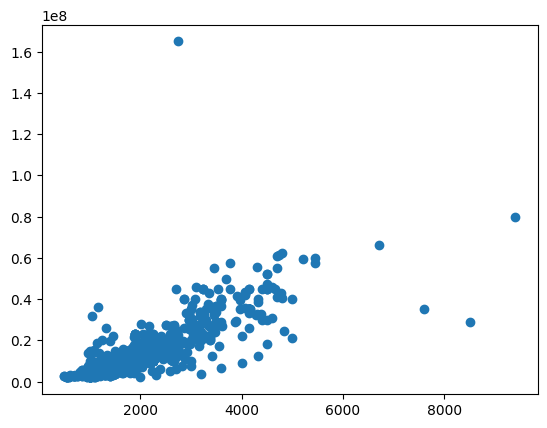

In [43]:
plt.scatter(data["Area"], data["Price"])

In [44]:
# Extract features (X) and target (y)
X = data[['Area']]  # Feature: Area
y = data['Price']  # Target: Price

# Create a Linear Regression model
simple_model = LinearRegression()

# Fit the model to the data
simple_model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9753.94]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-6.223e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [45]:
print(f"Slope (price_per_area): {simple_model.coef_[0]}")   # coefficient of Area
print(f"y-intercept (Base price): {simple_model.intercept_}")

Slope (price_per_area): 9753.94060818404
y-intercept (Base price): -6222669.083283702


c:\Users\pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


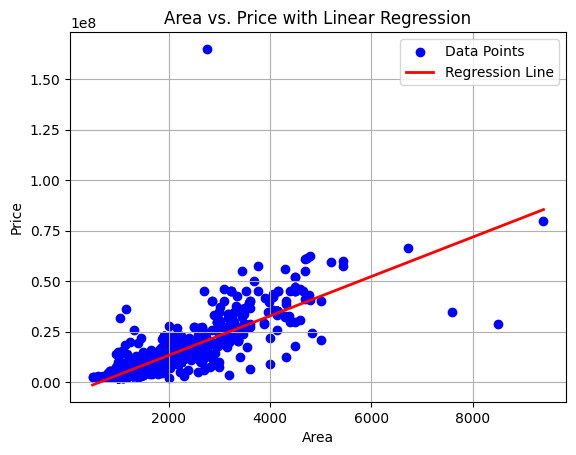

In [46]:
# Predict prices for a range of Area values to plot the regression line
area_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
predicted_prices = simple_model.predict(area_range)

# Plot the original data points
plt.scatter(X, y, color='blue', label='Data Points')

# Plot the regression line
plt.plot(area_range, predicted_prices, color='red', linewidth=2, label='Regression Line')

# Add labels and title
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Area vs. Price with Linear Regression')
plt.legend()

# Show the plot
plt.grid(True)
plt.show()

### Linear regression in Scikit-Learn

In [47]:
# Reshape the features to be a 2D array, which is required by scikit-learn
features_reshaped = features.reshape(-1, 1)

In [48]:
# Create a Linear Regression model
model = LinearRegression()

# Fit the model to the data
model.fit(features_reshaped, labels)

# Print the coefficients and intercept
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [50.39285714]
Intercept: 99.59523809523819


In [49]:
# Make a prediction for a new point
new_point = np.array([[4]])  # Predict for a feature value of 4
predicted_label = model.predict(new_point)
print("Predicted label for feature 4:", predicted_label)

Predicted label for feature 4: [301.16666667]


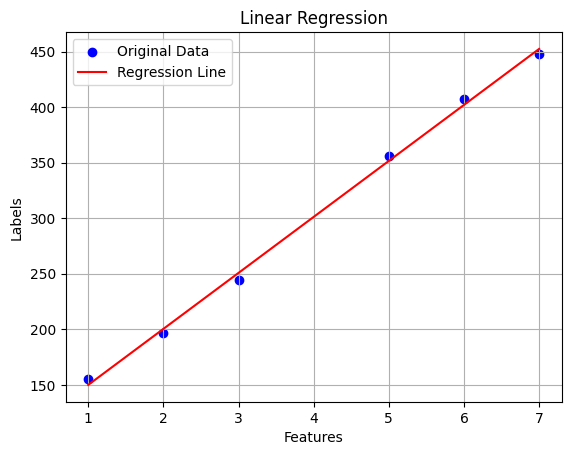

In [50]:
# Plot the results

# Generate the predicted values using the model
predicted_labels = model.predict(features_reshaped)
# Plot the original points
plt.scatter(features, labels, color='blue', label='Original Data')
# Plot the regression line
plt.plot(features, predicted_labels, color='red', label='Regression Line')
plt.xlabel('Features')
plt.ylabel('Labels')
plt.title('Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

### Building a model that uses all the features

In [51]:
data

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,6968000,1340,Nizampet,2,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
1,29000000,3498,Hitech City,4,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
2,6590000,1318,Manikonda,2,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5739000,1295,Alwal,3,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,5679000,1145,Kukatpally,2,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2513,11000000,1460,Nacharam,2,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
2514,26000000,1314,Manikonda,2,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
2515,13300000,2625,Madhapur,3,1,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
2516,10800000,2050,Hitech City,3,0,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9


_____
#### Pre-processing the data
In order to train a model in scikit-learn, we need to pre-process the data:
1. Remove missing values
2. Scale and center the numerical features
3. One-hot encode the categorical features

In [52]:
# First, we remove the bottom rows, which have missing data (encoded as '9')
data_truncated = data[:2434]
data_truncated

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,6968000,1340,Nizampet,2,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
1,29000000,3498,Hitech City,4,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
2,6590000,1318,Manikonda,2,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5739000,1295,Alwal,3,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,5679000,1145,Kukatpally,2,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2429,4500000,1250,Kollur Road,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2430,3503000,1001,Miyapur,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2431,5600000,1551,chandrayangutta,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2432,7500000,3000,Jubilee Hills,3,1,1,0,0,1,0,...,0,1,1,0,0,0,0,0,0,0


____
##### Standard Deviation (STD)

$$
\sigma = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(x_i-\mu)^2}
$$

Measures how spread out values are from their mean. A larger STD indicates greater spread; a smaller STD indicates values are closer to the mean.

In [53]:
# Scaling and centering the numerical features

data_scaled = data_truncated.copy()

# Calculate mean and standard deviation for 'Area'
area_mean = data_scaled['Area'].mean()
area_std = data_scaled['Area'].std()

# Scale and center 'Area'
data_scaled['Area'] = (data_scaled['Area'] - area_mean) / area_std

# Calculate mean and standard deviation for 'No. of Bedrooms'
bedrooms_mean = data_scaled['No. of Bedrooms'].mean()
bedrooms_std = data_scaled['No. of Bedrooms'].std()

# Scale and center 'No. of Bedrooms'
data_scaled['No. of Bedrooms'] = (data_scaled['No. of Bedrooms'] - bedrooms_mean) / bedrooms_std

# Print the head of the new dataframe to verify
print(data_scaled.head())

      Price      Area     Location  No. of Bedrooms  Resale  MaintenanceStaff  \
0   6968000 -0.406547     Nizampet        -0.913997       0                 0   
1  29000000  2.477960  Hitech City         2.005515       0                 0   
2   6590000 -0.435953    Manikonda        -0.913997       0                 0   
3   5739000 -0.466696        Alwal         0.545759       1                 0   
4   5679000 -0.667195   Kukatpally        -0.913997       0                 0   

   Gymnasium  SwimmingPool  LandscapedGardens  JoggingTrack  ...  \
0          1             1                  1             1  ...   
1          1             1                  1             1  ...   
2          1             0                  0             0  ...   
3          0             0                  0             0  ...   
4          0             0                  1             0  ...   

   LiftAvailable  BED  VaastuCompliant  Microwave  GolfCourse  TV  \
0              1    0              

____
#### Feature Standardization

Standardization transforms numerical features using the z-score formula:

$$
z = \frac{x-\mu}{\sigma}
$$

- $x$: Original value
- $\mu$: Feature mean
- $\sigma$: Feature standard deviation

**Purpose:** Centers values around 0 and scales them to have a standard deviation of 1, helping features operate on comparable scales during machine learning.

_____
#### One-Hot Encoding
`pd.get_dummies()` creates a separate column for each unique location, assigning 1 if the row belongs to that location and 0 otherwise.

This prevents the model from interpreting locations as numerical rankings (e.g., Lagos = 1, Abuja = 2, Ibadan = 3), which would falsely imply that one location is greater than another.

In [54]:
# One-hot encoding the Location feature

data_scaled_encoded = pd.get_dummies(data_scaled, columns=["Location"], prefix="Location", dtype=int)

In [55]:
print(data_scaled_encoded.head())

      Price      Area  No. of Bedrooms  Resale  MaintenanceStaff  Gymnasium  \
0   6968000 -0.406547        -0.913997       0                 0          1   
1  29000000  2.477960         2.005515       0                 0          1   
2   6590000 -0.435953        -0.913997       0                 0          1   
3   5739000 -0.466696         0.545759       1                 0          0   
4   5679000 -0.667195        -0.913997       0                 0          0   

   SwimmingPool  LandscapedGardens  JoggingTrack  RainWaterHarvesting  ...  \
0             1                  1             1                    1  ...   
1             1                  1             1                    1  ...   
2             0                  0             0                    0  ...   
3             0                  0             0                    0  ...   
4             0                  1             0                    0  ...   

   Location_Zamistanpur  Location_chandrayangutta  \
0  

___
### Fit a Linear Regression model

**X_full = ...drop('Price', axis=1)** — separates the input features from the target by removing the Price column.

In [56]:
# Separate features (X) and target (y) from the scaled and encoded data
# 'Price' is the target variable
X_full = data_scaled_encoded.drop('Price', axis=1)
y_full = data_scaled_encoded['Price']

# Create a Linear Regression model
model_predict_all = LinearRegression()

# Fit the model to the data
model_predict_all.fit(X_full, y_full)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](277,)","[ 7023504.92, -946893.4 , 1243472.5 ,..., 35774.09, -229036.36, -1150206.25]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](277,)","['Area','No. of Bedrooms','Resale',...,'Location_nizampet road', 'Location_raidurgam','Location_west venkatapuram']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.947e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,277
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,276


In [57]:
# Print the coefficients of the model

print("\nLinear Regression Model Coefficients (Predicting Price/ft from all features):")
print(f"Intercept: {model_predict_all.intercept_}")
print("Coefficients for features:")
for feature, coef in zip(X_full.columns, model_predict_all.coef_):
    print(f"{feature}: {coef}")


Linear Regression Model Coefficients (Predicting Price/ft from all features):
Intercept: 8947283.554193467
Coefficients for features:
Area: 7023504.920884538
No. of Bedrooms: -946893.3983315115
Resale: 1243472.4988407094
MaintenanceStaff: -1009480.5088404613
Gymnasium: -566573.4677680125
SwimmingPool: -74999.96382640209
LandscapedGardens: 888197.410120937
JoggingTrack: -617116.7707485193
RainWaterHarvesting: -499674.763743006
IndoorGames: 381986.01702800393
ShoppingMall: 653904.5052250414
Intercom: -129946.5764191011
SportsFacility: -14343.905357510084
ATM: -267074.49472984957
ClubHouse: 379591.68603432
School: -2597664.643518218
24X7Security: -144163.5423385012
PowerBackup: 164439.46341785137
CarParking: -227003.39319312503
StaffQuarter: 514965.4071233091
Cafeteria: 1170792.4549189417
MultipurposeRoom: 338851.72003292176
Hospital: 1864174.8390719278
WashingMachine: 708354.332059094
Gasconnection: 770551.9359812485
AC: 560593.5481483054
Wifi: 807040.4215051098
Children'splayarea: 8167

In [58]:
# Use the model to make Price predictions
y_pred = model_predict_all.predict(X_full)

# Evaluate the model
mse = mean_squared_error(y_full, y_pred)
rmse_value = np.sqrt(mse)
print(f"\nRoot Mean Squared Error (RMSE) of the model: {rmse_value}")


Root Mean Squared Error (RMSE) of the model: 3981396.2916407348


It may take a few moments to train, but after it trains, we can look at some
information, such as the root mean square error. For this model, the RMSE is
close to 4,000,000. This is a large RMSE, but it doesn’t mean the model
makes bad predictions. It may mean that the dataset has many outliers. 

As
you can imagine, the price of a house may depend on many other features
that are not in the dataset.
______

**X_full.loc[0]** selects the row whose index label is 0 from the X_full DataFrame.

In [59]:
X_full.loc[0]

Area                         -0.406547
No. of Bedrooms              -0.913997
Resale                        0.000000
MaintenanceStaff              0.000000
Gymnasium                     1.000000
                                ...   
Location_muthangi             0.000000
Location_new nallakunta       0.000000
Location_nizampet road        0.000000
Location_raidurgam            0.000000
Location_west venkatapuram    0.000000
Name: 0, Length: 277, dtype: float64

____
We can use the model to predict the price of a house with an area of 1,000,
and three bedrooms, in the location of Gachibowli (see notebook). The
model outputs that the predicted price for this house is 6,006,016.

In [60]:
# prompt: use the model_predict_all to predict the price of a house with size 1000 and 3 bedrooms

# To predict for a new house, we need to create a DataFrame with the same columns as X_full
# and apply the same scaling and encoding steps.

# New house data
new_house_data = pd.DataFrame({'Area': [1000], 'No. of Bedrooms': [3]})

# We need to apply the same scaling used for the training data
new_house_data['Area'] = (new_house_data['Area'] - area_mean) / area_std
new_house_data['No. of Bedrooms'] = (new_house_data['No. of Bedrooms'] - bedrooms_mean) / bedrooms_std

# For location, we assume a default location or one that was present in the training data.
# If we don't specify a location that was in the training data, the one-hot encoding
# will not create a column for that location, which will cause an error when predicting.
# Let's assume the new house is in 'Gachibowli', which was likely in the training data.
# If the location is unknown or not in the training data, we would need to handle this,
# e.g., by adding a column of zeros for that location or using a different approach.

# Create a dummy DataFrame with all possible location columns initialized to 0
# based on the columns of X_full that start with 'Location_'
location_cols = [col for col in X_full.columns if col.startswith('Location_')]
new_house_location_dummies = pd.DataFrame(0, index=new_house_data.index, columns=location_cols)

# Assuming the new house is in 'Gachibowli', set the corresponding column to 1
# Check if 'Location_Gachibowli' exists in the trained model's features
if 'Location_Gachibowli' in location_cols:
    new_house_location_dummies['Location_Gachibowli'] = 1
else:
    print("Warning: 'Location_Gachibowli' was not found in the training data locations.")
    # Handle cases where the location is not in the training data if necessary
    # For this example, we'll proceed without setting a specific location if it's not found.

# Combine the scaled features with the location dummy variables
# Ensure all columns from X_full are present, adding missing ones with value 0
new_house_processed = pd.concat([new_house_data, new_house_location_dummies], axis=1)

# Ensure the order and presence of columns match X_full exactly
# This is crucial for the prediction to work correctly
for col in X_full.columns:
    if col not in new_house_processed.columns:
        new_house_processed[col] = 0 # Add missing columns with value 0

# Reorder columns to match X_full
new_house_processed = new_house_processed[X_full.columns]


# Predict the price using the trained model
predicted_price = model_predict_all.predict(new_house_processed)

print(f"\nPredicted price for a house with size 1000 and 3 bedrooms: {predicted_price[0]:,.2f}")


Predicted price for a house with size 1000 and 3 bedrooms: 6,004,735.31


_____
**Key idea:** New data must undergo the same preprocessing as training data before prediction.

**.columns** returns the column names of a DataFrame.

It provides the actual column names in their original order. Pandas then selects those columns from new_house_processed in that exact order.
It works because the previous loop already ensured that every required column exists.

____
#### EXERCISE 3.3

$ p = 2s + 50$

In [61]:
sizes = np.array([100, 200, 200, 250, 325]) # features
prices = np.array([200, 475, 400, 520, 735]) # labels

Price per room:  2.171725131060478
Base price:  0.4073904445657502


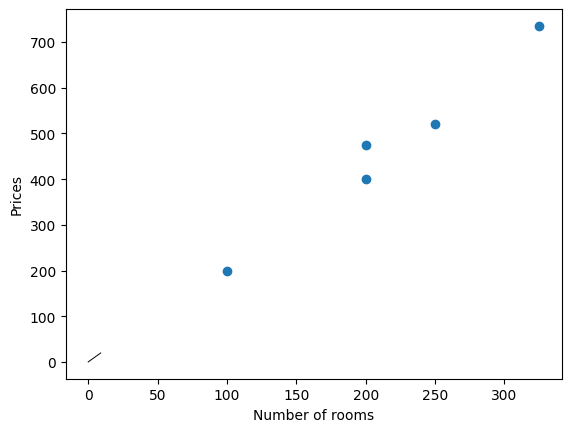

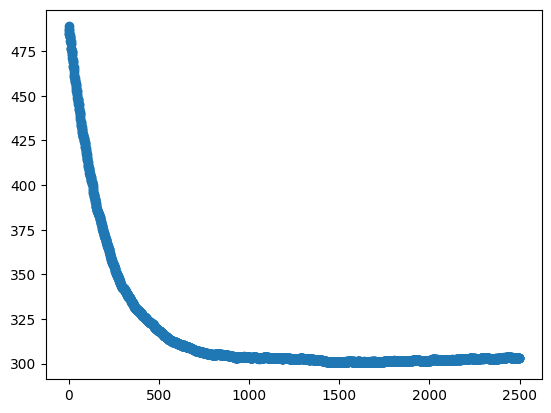

(np.float64(2.171725131060478), np.float64(0.4073904445657502))

In [64]:
linear_regression(sizes, prices, learning_rate=0.0000001, epochs=2500)